# Lab: Clean the Messy Text (NLP Basics)
### PSEB AI Bootcamp

This notebook contains all four parts of the lab, the "Check your understanding" answers, and the opinion paragraph. All outputs are saved so it can be submitted as-is. To run it yourself, open it in Google Colab and use **Runtime → Run all**.

## Check your understanding

| # | Question | Your answer |
|---|----------|-------------|
| 1 | Why do we clean text before giving it to a computer? | A computer only sees raw characters, not meaning. Cleaning puts the text into one consistent, simple form so the model can learn real patterns instead of wasting effort on capital letters, punctuation, links and other noise. |
| 2 | What do you get if you normalize "I LOVE this Movie!!! :)"? | `i love this movie` — everything is lowercase, the exclamation marks and smiley are gone, and the extra spaces are collapsed. |
| 3 | How many tokens are in "good morning class"? | 3 tokens: `good`, `morning`, `class`. |
| 4 | Which words in "this is a very good lab" are stopwords? | `this`, `is`, `a` and `very` (all four are in the NLTK English stopword list). The content words left are `good` and `lab`. |
| 5 | Which one turns "went" into "go": stemming or lemmatization? Why? | Lemmatization, when we tell it the word is a verb (`lemmatize("went", pos="v")`). It uses a dictionary that knows "went" is the past tense of "go"; a stemmer only chops letters and leaves "went" unchanged. |
| 6 | Why can removing stopwords be risky for "I did not like it"? | `not` is in most stopword lists. If we delete it, the sentence becomes "I like it" and the sentiment flips from negative to positive. |

## Setup — starter data

I import the tools, download the NLTK resources, and keep the six messy sentences from the lab. I also download the POS tagger because the final pipeline uses POS-aware lemmatization (the reason is explained in Part 3).

In [1]:
import re
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')       # extra: needed for POS-aware lemmatization
nltk.download('averaged_perceptron_tagger_eng')   # extra: NLTK 3.9+ name for the same model

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk import pos_tag
from nltk.stem import PorterStemmer, WordNetLemmatizer

messy = [
 "OMG!! I can't believe this bootcamp is sooo good 😂😂 #AI",
 "Check out https://example.com for NLP notes!!! RT @friend",
 "We live in the US, and the Us team doesn't like us.",
 "He's going, she went, they goes... and I have gone 😅",
 "I did NOT like this movie. Not good at all!!",
 "Price was 9.99$ and rating 4.5/5 :) :p",
]

print("Ready:", len(messy), "messy sentences")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Uzair\AppData\Roaming\nltk_data...


[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Uzair\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Uzair\AppData\Roaming\nltk_data...


[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Uzair\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Uzair\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\Uzair\AppData\Roaming\nltk_data...


[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\Uzair\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\Uzair\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


Ready: 6 messy sentences


## Part 1 — Normalize

I wrote `normalize(text)` that lowercases, expands contractions first (so `can't` becomes `cannot` instead of `can t`), then removes URLs, @mentions, hashtags, emoji and text smileys, then strips the remaining punctuation and collapses extra spaces with `re.sub`. I remove the whole hashtag token as the lab asks; in a real project you might keep the word `AI` and only drop the `#`.

In [2]:
CONTRACTIONS = {
    "can't": "cannot", "won't": "will not", "shan't": "shall not",
    "i'm": "i am", "he's": "he is", "she's": "she is", "it's": "it is",
    "that's": "that is", "what's": "what is", "there's": "there is",
    "i've": "i have", "you've": "you have", "we've": "we have", "they've": "they have",
    "i'll": "i will", "you'll": "you will", "he'll": "he will", "she'll": "she will",
    "we'll": "we will", "they'll": "they will",
    "i'd": "i would", "you'd": "you would", "he'd": "he would", "she'd": "she would",
    "we'd": "we would", "they'd": "they would",
    "isn't": "is not", "aren't": "are not", "wasn't": "was not", "weren't": "were not",
    "don't": "do not", "doesn't": "does not", "didn't": "did not",
    "haven't": "have not", "hasn't": "has not", "hadn't": "had not",
    "couldn't": "could not", "shouldn't": "should not", "wouldn't": "would not",
    "mustn't": "must not", "let's": "let us", "you're": "you are",
    "we're": "we are", "they're": "they are",
}

EMOJI_RE = re.compile(
    "["
    "\U0001F1E6-\U0001F1FF\U0001F300-\U0001F5FF\U0001F600-\U0001F64F"
    "\U0001F680-\U0001F6FF\U0001F900-\U0001F9FF\U0001FA00-\U0001FAFF"
    "\U00002700-\U000027BF\U00002600-\U000026FF\uFE0F"
    "]+", flags=re.UNICODE
)
TEXT_SMILEY_RE = re.compile(r"(?::|;|=|8|x)(?:-|\^)?(?:\)|\(|d|D|p|P|/|\\|\||\])")

def normalize(text):
    # 1. one style: lowercase and standard apostrophes
    text = text.lower().replace("\u2019", "'")

    # 2. expand contractions before punctuation is removed
    for short, long in CONTRACTIONS.items():
        text = re.sub(r"\b" + re.escape(short) + r"\b", long, text)

    # 3. remove links, mentions, hashtags, emoji and text smileys
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"#\w+", " ", text)
    text = EMOJI_RE.sub(" ", text)
    text = TEXT_SMILEY_RE.sub(" ", text)

    # 4. remove remaining punctuation/symbols and tidy whitespace
    text = re.sub(r"[^\w\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

normalized = [normalize(s) for s in messy]
display(pd.DataFrame({
    "before": messy,
    "after": normalized,
}))

,before,after
0,OMG!! I can't believe this bootcamp is sooo go...,omg i cannot believe this bootcamp is sooo good
1,Check out https://example.com for NLP notes!!!...,check out for nlp notes rt
2,"We live in the US, and the Us team doesn't lik...",we live in the us and the us team does not lik...
3,"He's going, she went, they goes... and I have ...",he is going she went they goes and i have gone
4,I did NOT like this movie. Not good at all!!,i did not like this movie not good at all
5,Price was 9.99$ and rating 4.5/5 :) :p,price was 9 99 and rating 4 5 5


## Part 2 — Tokenize and remove stopwords

I used `word_tokenize` on the normalized text and dropped the NLTK English stopwords. My two custom stopwords are **`rt`** (a retweet marker in sentence 2 — it describes how the post travelled, not what it means) and **`omg`** (an exclamation in sentence 1 that carries emotion but no topic meaning). I also keep negation words such as `not`, because otherwise "not good" would turn into "good"; the comparison below shows exactly that.

In [3]:
STOPWORDS = set(stopwords.words("english"))
CUSTOM_STOPWORDS = {"rt", "omg"}          # my two custom stopwords
NEGATIONS = {"not", "no", "nor", "never", "none"}

def tokenize_and_filter(text, keep_negations=True):
    tokens = word_tokenize(text)
    drop = set(STOPWORDS) | CUSTOM_STOPWORDS
    if keep_negations:
        drop = drop - NEGATIONS            # protect meaning-changing words
    return [t for t in tokens if t not in drop and t.strip()]

filtered = [tokenize_and_filter(t) for t in normalized]
display(pd.DataFrame({
    "normalized": normalized,
    "tokens_after_stopwords": filtered,
}))

print("Trap check on sentence 5:")
print("  keeping  not ->", tokenize_and_filter(normalized[4], keep_negations=True))
print("  removing not ->", tokenize_and_filter(normalized[4], keep_negations=False))

,normalized,tokens_after_stopwords
0,omg i cannot believe this bootcamp is sooo good,"[not, believe, bootcamp, sooo, good]"
1,check out for nlp notes rt,"[check, nlp, notes]"
2,we live in the us and the us team does not lik...,"[live, us, us, team, not, like, us]"
3,he is going she went they goes and i have gone,"[going, went, goes, gone]"
4,i did not like this movie not good at all,"[not, like, movie, not, good]"
5,price was 9 99 and rating 4 5 5,"[price, 9, 99, rating, 4, 5, 5]"


Trap check on sentence 5:
  keeping  not -> ['not', 'like', 'movie', 'not', 'good']
  removing not -> ['like', 'movie', 'good']


## Part 3 — Stemming vs lemmatization

I ran the eight words through `PorterStemmer` and `WordNetLemmatizer` and put the results in a pandas table with the required columns `word`, `stem`, `lemma`. I also show what happens when the lemmatizer is told the word is a verb (`pos="v"`), because that is the only way it turns `went` into `go`.

In [4]:
words = ["go", "goes", "going", "gone", "went", "studies", "better", "running"]
stemmer = PorterStemmer()
lem = WordNetLemmatizer()

stem_table = pd.DataFrame({
    "word": words,
    "stem": [stemmer.stem(w) for w in words],
    "lemma": [lem.lemmatize(w) for w in words],   # default, no POS information
})
display(stem_table)

pos_table = pd.DataFrame({
    "word": words,
    "lemma (no pos)": [lem.lemmatize(w) for w in words],
    "lemma (pos='v')": [lem.lemmatize(w, pos="v") for w in words],
})
display(pos_table)

,word,stem,lemma
0,go,go,go
1,goes,goe,go
2,going,go,going
3,gone,gone,gone
4,went,went,went
5,studies,studi,study
6,better,better,better
7,running,run,running


,word,lemma (no pos),lemma (pos='v')
0,go,go,go
1,goes,go,go
2,going,going,go
3,gone,gone,go
4,went,went,go
5,studies,study,study
6,better,better,better
7,running,running,run


**Which looked more correct?** Lemmatization: `studies → study` is a real word, while the stemmer gives the non-word `studi`, and with `pos="v"` it also gets `goes / going / gone / went → go`.

**But note the catch:** with no POS information the lemmatizer leaves `went`, `going` and `gone` unchanged, so it needs the word type before it can be trusted — that is why the final pipeline uses POS tags.

## Part 4 — Full pipeline and mini analysis

I joined the steps in the required order: **normalize → tokenize → remove stopwords → lemmatize**. The lemmatizer uses POS tags from `pos_tag`, with a small guard that leaves `us`, `u` and `i` alone (WordNet would otherwise change `us` into `u`, and lowercasing has already merged `US` and `us` — one of the lecture's traps).

In [5]:
def wordnet_pos(treebank_tag):
    if treebank_tag.startswith("J"):
        return wordnet.ADJ
    if treebank_tag.startswith("V"):
        return wordnet.VERB
    if treebank_tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

KEEP_AS_IS = {"us", "u", "i"}

def lemmatize_tokens(tokens):
    return [t if t in KEEP_AS_IS else lem.lemmatize(t, wordnet_pos(tag))
            for t, tag in pos_tag(tokens)]

def full_pipeline(text, keep_negations=True):
    clean_text = normalize(text)
    tokens = tokenize_and_filter(clean_text, keep_negations)
    return lemmatize_tokens(tokens)

clean_sentences = [full_pipeline(s) for s in messy]
for original, clean in zip(messy, clean_sentences):
    print(original, "\n  ->", clean, "\n")

OMG!! I can't believe this bootcamp is sooo good 😂😂 #AI 
  -> ['not', 'believe', 'bootcamp', 'sooo', 'good'] 

Check out https://example.com for NLP notes!!! RT @friend 
  -> ['check', 'nlp', 'note'] 

We live in the US, and the Us team doesn't like us. 
  -> ['live', 'us', 'us', 'team', 'not', 'like', 'us'] 

He's going, she went, they goes... and I have gone 😅 
  -> ['go', 'go', 'go', 'go'] 

I did NOT like this movie. Not good at all!! 
  -> ['not', 'like', 'movie', 'not', 'good'] 

Price was 9.99$ and rating 4.5/5 :) :p 
  -> ['price', '9', '99', 'rating', '4', '5', '5'] 



### Word counts before and after cleaning

"Before" is the number of whitespace-separated chunks in the raw sentence; "after" is the number of tokens left at the end of the pipeline.

In [6]:
count_table = pd.DataFrame({
    "sentence": messy,
    "words before": [len(s.split()) for s in messy],
    "words after": [len(tokens) for tokens in clean_sentences],
})
count_table["removed"] = count_table["words before"] - count_table["words after"]
display(count_table)

all_tokens = [t for tokens in clean_sentences for t in tokens]
print("Total tokens after cleaning:", len(all_tokens))
print("Top 10:", pd.Series(all_tokens).value_counts().head(10).to_dict())

,sentence,words before,words after,removed
0,OMG!! I can't believe this bootcamp is sooo go...,11,5,6
1,Check out https://example.com for NLP notes!!!...,8,3,5
2,"We live in the US, and the Us team doesn't lik...",12,7,5
3,"He's going, she went, they goes... and I have ...",11,4,7
4,I did NOT like this movie. Not good at all!!,10,5,5
5,Price was 9.99$ and rating 4.5/5 :) :p,8,7,1


Total tokens after cleaning: 31
Top 10: {'not': 4, 'go': 4, 'us': 3, 'good': 2, 'like': 2, '5': 2, 'believe': 1, 'bootcamp': 1, 'sooo': 1, 'check': 1}


### Bar chart of the 10 most common words after cleaning

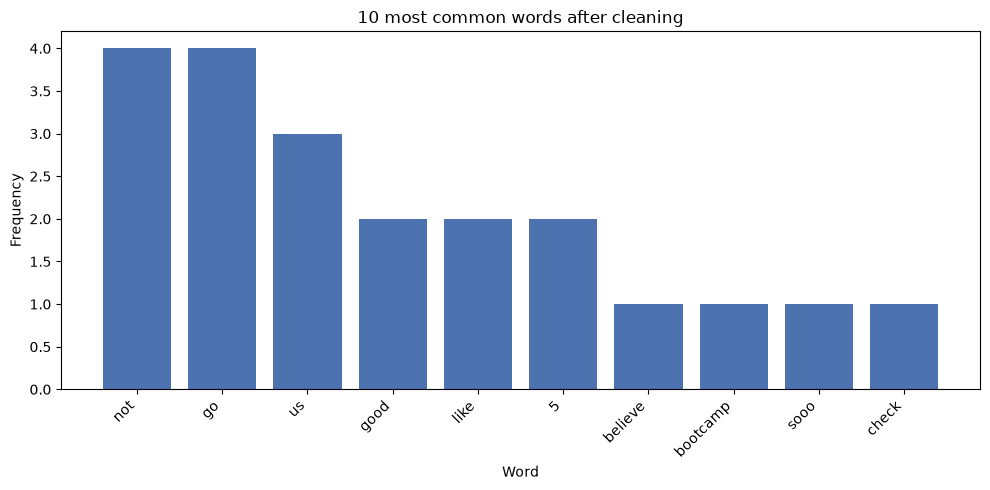

In [7]:
%matplotlib inline

top10 = pd.Series(all_tokens).value_counts().head(10)
plt.figure(figsize=(10, 5))
plt.bar(top10.index, top10.values, color="#4C72B0")
plt.title("10 most common words after cleaning")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Write your opinion — Topic 1: Do stopwords always help?

Removing stopwords does **not** always help, because a word can be "common" and still carry the whole meaning of a sentence. The clearest example is in this lab: sentence 5 is "I did NOT like this movie. Not good at all!!". When I remove NLTK stopwords the usual way, `not` disappears and the result is `like movie good` — a negative review has quietly become a positive one. That is why my `tokenize_and_filter` keeps negation words: the cleaned version `not like movie not good` still says what the writer meant. In real life the same thing happens in a school feedback form: "not good" and "good" must never collapse into the same text. A sensible rule is to remove stopwords for tasks like topic modelling or counting words, but to keep words such as `not`, `no` and `never` for sentiment analysis, and to check a few examples by eye before trusting the output. Cleaning is a set of choices, not a recipe you can follow without thinking.